# PHK Perusahaan Teknologi Global 2020–2023: Data Cleaning & EDA dengan Python

**Pertanyaan utama:** kapan gelombang PHK memuncak, siapa yang paling terdampak (perusahaan, industri, negara, tahap pendanaan), dan seberapa besar PHK yang "biasa" terjadi?

Data: 2.361 kejadian PHK (11 Maret 2020 – 6 Maret 2023) dari [Layoffs.fyi](https://layoffs.fyi) melalui repo [Alex The Analyst](https://github.com/AlexTheAnalyst/MySQL-YouTube-Series).
Data yang sama sudah saya bersihkan dan analisis dengan **MySQL** di [Proyek 2](https://github.com/DEWI1717/sql-world-layoffs). Di sini saya mengulanginya dengan **pandas** dan menambahkan **visualisasi**.

**Tools:** Python 3.11 · pandas · matplotlib · seaborn

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

sns.set_theme(style="whitegrid")
WARNA = "#2B7BD6"

def ribuan(x, pos=None):
    """Format angka gaya Indonesia: 12000 -> 12.000"""
    return f"{x:,.0f}".replace(",", ".")

def simpan(nama):
    plt.tight_layout()
    plt.savefig(f"gambar/{nama}.png", dpi=120)
    plt.show()

## 1. Data cleaning
Semua langkah sama dengan `data_cleaning.sql` di Proyek 2, sehingga hasil akhirnya bisa dicocokkan: **1.995 baris**.

In [2]:
raw = pd.read_csv("data/layoffs_raw.csv")   # teks "NULL" otomatis dibaca sebagai kosong (NaN)
print("Ukuran data mentah:", raw.shape)
raw.head()

Ukuran data mentah: (2361, 9)


,company,location,industry,total_laid_off,percentage_laid_off,date,stage,country,funds_raised_millions
0,Atlassian,Sydney,Other,500.0,0.05,3/6/2023,Post-IPO,Australia,210.0
1,SiriusXM,New York City,Media,475.0,0.08,3/6/2023,Post-IPO,United States,525.0
2,Alerzo,Ibadan,Retail,400.0,NaN,3/6/2023,Series B,Nigeria,16.0
3,UpGrad,Mumbai,Education,120.0,NaN,3/6/2023,Unknown,India,631.0
4,Loft,Sao Paulo,Real Estate,340.0,0.15,3/3/2023,Unknown,Brazil,788.0


### Langkah 1: hapus duplikat
Baris yang **semua kolomnya sama persis** dianggap duplikat.

In [3]:
df = raw.drop_duplicates().copy()
print("Duplikat dihapus:", len(raw) - len(df), "| sisa:", len(df))

Duplikat dihapus: 5 | sisa: 2356


### Langkah 2: standarisasi
- `company`: buang spasi di awal/akhir
- `industry`: "Crypto", "Crypto Currency", "CryptoCurrency" → satu nama **Crypto**
- `country`: "United States." → "United States"
- `date`: teks bulan/hari/tahun → tipe tanggal

In [4]:
print("Variasi Crypto sebelum:", sorted(df.loc[df["industry"].str.startswith("Crypto", na=False), "industry"].unique()))
print("Variasi United States sebelum:", sorted(df.loc[df["country"].str.startswith("United States"), "country"].unique()))

df["company"] = df["company"].str.strip()
df.loc[df["industry"].str.startswith("Crypto", na=False), "industry"] = "Crypto"
df["country"] = df["country"].str.rstrip(".")
df["date"] = pd.to_datetime(df["date"], format="%m/%d/%Y")

print("Rentang tanggal:", df["date"].min().date(), "s.d.", df["date"].max().date(),
      "| tanpa tanggal:", df["date"].isna().sum())

Variasi Crypto sebelum: ['Crypto', 'Crypto Currency', 'CryptoCurrency']
Variasi United States sebelum: ['United States', 'United States.']
Rentang tanggal: 2020-03-11 s.d. 2023-03-06 | tanpa tanggal: 1


### Langkah 3: isi `industry` yang kosong
Kalau perusahaan yang sama punya baris lain dengan industri terisi, pakai industri itu. Kalau tidak ada sumbernya, **biarkan kosong** (lebih jujur daripada menebak).

In [5]:
kosong = df[df["industry"].isna()]["company"].tolist()
print("Industry kosong:", kosong)

df["industry"] = df["industry"].fillna(df.groupby("company")["industry"].transform("first"))
print("Masih kosong:", df[df["industry"].isna()]["company"].tolist())

Industry kosong: ['Airbnb', "Bally's Interactive", 'Juul', 'Carvana']
Masih kosong: ["Bally's Interactive"]


### Langkah 4: hapus baris tanpa informasi PHK
Baris yang `total_laid_off` **dan** `percentage_laid_off`-nya sama-sama kosong tidak bisa dianalisis.

In [6]:
sebelum = len(df)
df = df.dropna(subset=["total_laid_off", "percentage_laid_off"], how="all").reset_index(drop=True)
print("Dihapus:", sebelum - len(df), "| data bersih:", df.shape)

Dihapus: 361 | data bersih: (1995, 9)


**Hasil cleaning: 2.361 → 2.356 → 1.995 baris**, sama dengan hasil SQL Proyek 2. ✅

## 2. Exploratory Data Analysis
### Ringkasan

In [7]:
print("Total PHK           :", ribuan(df["total_laid_off"].sum()))
print("Jumlah perusahaan   :", ribuan(df["company"].nunique()))
print("PHK terbesar (1x)   :", ribuan(df["total_laid_off"].max()))
print("Kejadian PHK 100%   :", (df["percentage_laid_off"] == 1).sum())

Total PHK           : 383.659
Jumlah perusahaan   : 1.633
PHK terbesar (1x)   : 12.000
Kejadian PHK 100%   : 116


### Q1. Kapan gelombang PHK memuncak?

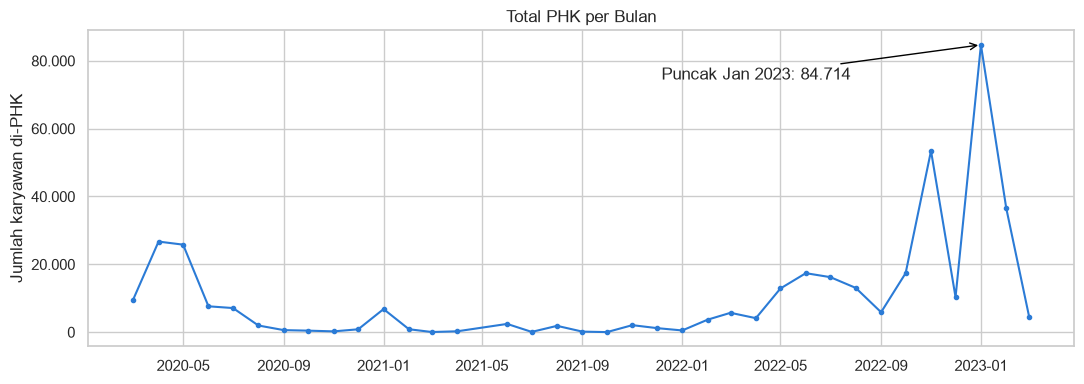

date
2020.0     80998
2021.0     15823
2022.0    160661
2023.0    125677
Name: total_laid_off, dtype: int64
Bulan tertinggi: January 2023 = 84.714


In [8]:
bulanan = df.groupby(df["date"].dt.to_period("M"))["total_laid_off"].sum()
bulanan.index = bulanan.index.to_timestamp()
puncak = bulanan.idxmax()

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(bulanan.index, bulanan.values, color=WARNA, marker="o", markersize=3)
ax.annotate(f"Puncak {puncak:%b %Y}: {ribuan(bulanan.max())}", xy=(puncak, bulanan.max()),
            xytext=(-230, -25), textcoords="offset points", arrowprops=dict(arrowstyle="->", color="black"))
ax.yaxis.set_major_formatter(mtick.FuncFormatter(ribuan))
ax.set_title("Total PHK per Bulan")
ax.set_xlabel(""); ax.set_ylabel("Jumlah karyawan di-PHK")
simpan("q1_phk_per_bulan")

per_tahun = df.groupby(df["date"].dt.year)["total_laid_off"].sum()
print(per_tahun.astype(int))
print("Bulan tertinggi:", f"{puncak:%B %Y}", "=", ribuan(bulanan.max()))

**Temuan:** ada dua gelombang. Gelombang pertama di awal pandemi (April–Mei 2020), lalu sepi di 2021.
Gelombang kedua jauh lebih besar: mulai pertengahan 2022, memuncak di **Januari 2023 (84.714 orang dalam satu bulan)**.
Data 2023 baru sampai 6 Maret, tetapi totalnya sudah 125.677, hampir menyamai seluruh tahun 2022 (160.661).

### Q2. Perusahaan mana yang mem-PHK paling banyak?

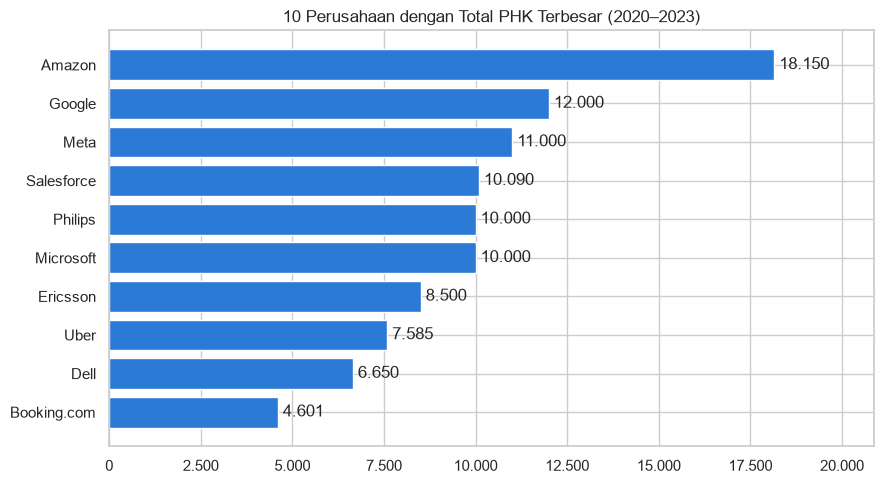

In [9]:
top_perusahaan = df.groupby("company")["total_laid_off"].sum().nlargest(10).sort_values()

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top_perusahaan.index, top_perusahaan.values, color=WARNA)
for i, v in enumerate(top_perusahaan.values):
    ax.text(v, i, " " + ribuan(v), va="center")
ax.margins(x=0.15)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(ribuan))
ax.set_title("10 Perusahaan dengan Total PHK Terbesar (2020–2023)")
simpan("q2_top_perusahaan")

**Temuan:** perusahaan teknologi raksasa mendominasi: **Amazon (18.150)**, Google (12.000), dan Meta (11.000). Google mem-PHK 12.000 orang dalam **satu** pengumuman (Januari 2023), kejadian PHK tunggal terbesar di data ini.

### Q3. Industri mana yang paling terdampak?

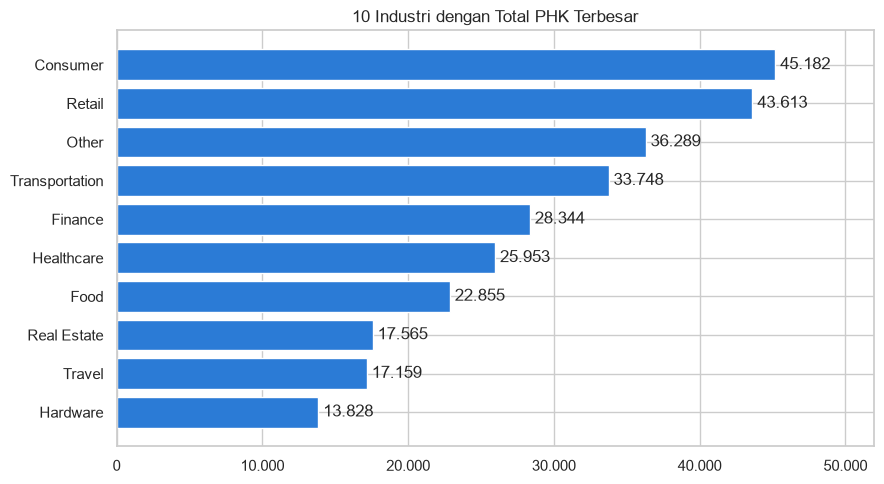

In [10]:
per_industri = df.groupby("industry")["total_laid_off"].sum().nlargest(10).sort_values()

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(per_industri.index, per_industri.values, color=WARNA)
for i, v in enumerate(per_industri.values):
    ax.text(v, i, " " + ribuan(v), va="center")
ax.margins(x=0.15)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(ribuan))
ax.set_title("10 Industri dengan Total PHK Terbesar")
simpan("q3_industri")

**Temuan:** **Consumer (45.182)** dan **Retail (43.613)** paling terdampak, yaitu bisnis yang sempat tumbuh pesat saat belanja online melonjak di masa pandemi.

### Q4. Negara mana yang paling terdampak?

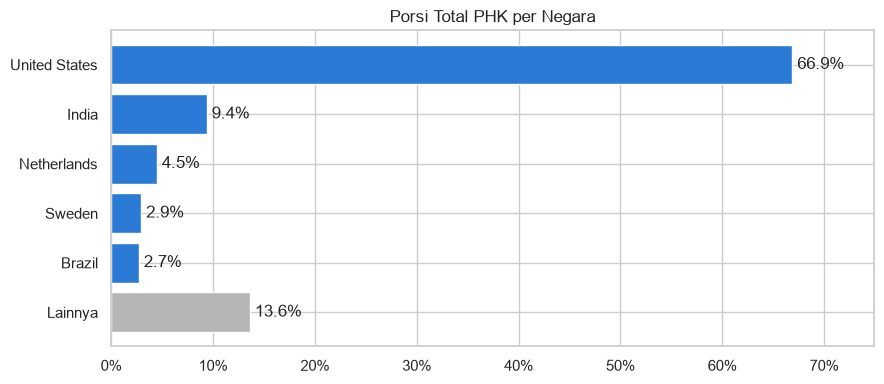

country
United States    256559
India             35993
Netherlands       17220
Sweden            11264
Brazil            10391
Name: total_laid_off, dtype: int64
Jumlah negara: 51


In [11]:
per_negara = df.groupby("country")["total_laid_off"].sum().sort_values(ascending=False)
porsi = per_negara / per_negara.sum() * 100
top5 = porsi.head(5)
lainnya = pd.Series({"Lainnya": porsi.iloc[5:].sum()})
tampil = pd.concat([lainnya, top5.sort_values()])

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(tampil.index, tampil.values, color=[WARNA if n != "Lainnya" else "#B5B5B5" for n in tampil.index])
for i, v in enumerate(tampil.values):
    ax.text(v, i, f" {v:.1f}%", va="center")
ax.margins(x=0.12)
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title("Porsi Total PHK per Negara")
simpan("q4_negara")
print(per_negara.head(5).astype(int))
print("Jumlah negara:", per_negara.size)

**Temuan:** **Amerika Serikat menyumbang 66,9%** dari seluruh PHK (256.559 orang), jauh di atas India (9,4%) dan Belanda (4,5%). Sebagian karena perusahaan teknologi besar berkantor pusat di sana, dan sebagian karena sumber datanya (Layoffs.fyi) lebih banyak mencatat berita dari AS.

### Q5. Apakah startup atau perusahaan besar yang paling banyak mem-PHK?

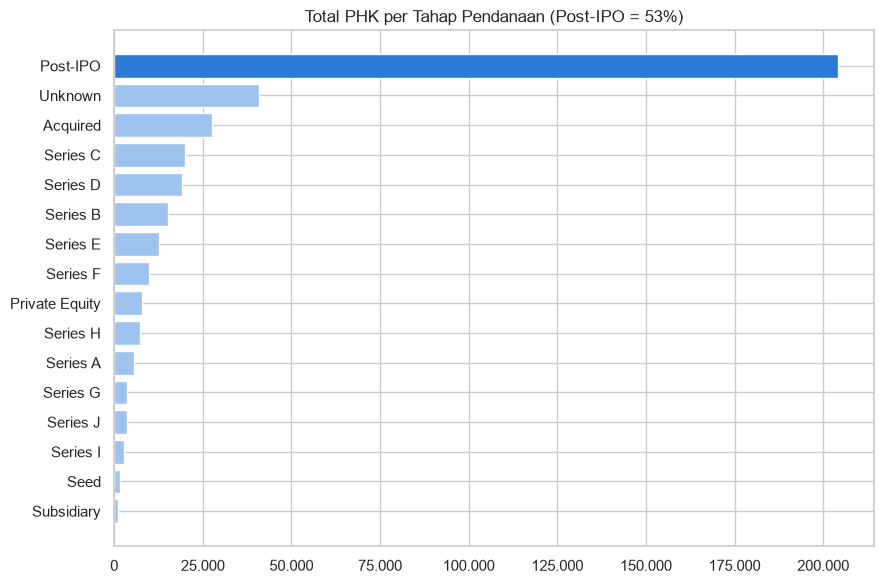

stage
Post-IPO    204132
Unknown      40716
Acquired     27576
Name: total_laid_off, dtype: int64


In [12]:
per_stage = df.groupby("stage")["total_laid_off"].sum().sort_values()
porsi_ipo = per_stage["Post-IPO"] / per_stage.sum() * 100

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(per_stage.index, per_stage.values, color=[WARNA if s == "Post-IPO" else "#9DC3EE" for s in per_stage.index])
ax.xaxis.set_major_formatter(mtick.FuncFormatter(ribuan))
ax.set_title(f"Total PHK per Tahap Pendanaan (Post-IPO = {porsi_ipo:.0f}%)")
simpan("q5_stage")
print(per_stage.sort_values(ascending=False).head(3).astype(int))

**Temuan:** perusahaan yang **sudah IPO (Post-IPO) menyumbang 204.132 PHK (53%)**. PHK paling banyak terjadi di perusahaan besar yang sudah melantai di bursa, bukan di startup tahap awal (Seed–Series B).

### Q6. Seberapa besar PHK yang "biasa" terjadi?

count     1617.0
mean       237.3
std        769.8
min          3.0
25%         36.0
50%         80.0
75%        180.0
max      12000.0
Name: total_laid_off, dtype: float64


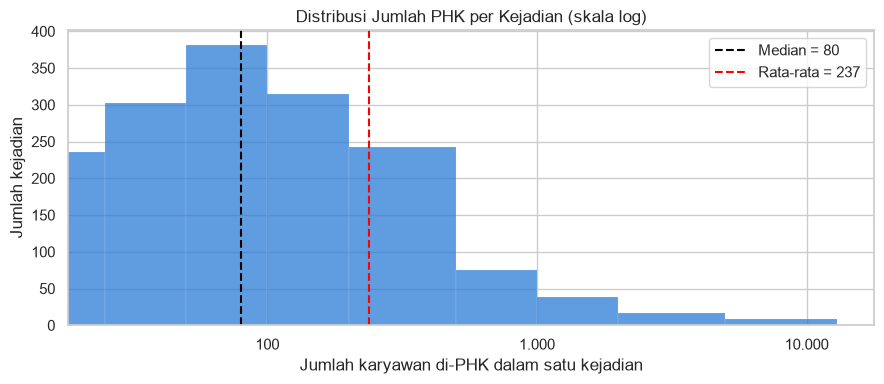

Kejadian <= 200 orang: 79%


In [13]:
t = df["total_laid_off"].dropna()
print(t.describe().round(1))

fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(t, bins=[0, 25, 50, 100, 200, 500, 1000, 2000, 5000, 13000], ax=ax, color=WARNA)
ax.set_xscale("log")
ax.axvline(t.median(), color="black", linestyle="--", label=f"Median = {t.median():.0f}")
ax.axvline(t.mean(), color="red", linestyle="--", label=f"Rata-rata = {t.mean():.0f}")
ax.xaxis.set_major_formatter(mtick.FuncFormatter(ribuan))
ax.set_title("Distribusi Jumlah PHK per Kejadian (skala log)")
ax.set_xlabel("Jumlah karyawan di-PHK dalam satu kejadian"); ax.set_ylabel("Jumlah kejadian")
ax.legend()
simpan("q6_distribusi")

print("Kejadian <= 200 orang:", f"{(t <= 200).mean() * 100:.0f}%")

**Temuan:** PHK yang "biasa" terjadi jauh lebih kecil dari yang diberitakan. **Median hanya 80 orang**, sedangkan rata-ratanya 237, karena tertarik ke atas oleh beberapa PHK raksasa (sampai 12.000).
Hampir 4 dari 5 kejadian PHK (79%) melibatkan **200 orang atau kurang**.

### Q7. Perusahaan bermodal besar yang tutup (PHK 100%)

In [14]:
tutup = df[df["percentage_laid_off"] == 1]
print("Kejadian PHK 100%:", len(tutup))
tutup.sort_values("funds_raised_millions", ascending=False)[["company", "industry", "country", "funds_raised_millions", "date"]].head(5)

Kejadian PHK 100%: 116


,company,industry,country,funds_raised_millions,date
288,Britishvolt,Transportation,United Kingdom,2400.0,2023-01-17
1477,Quibi,Media,United States,1800.0,2020-10-21
590,Deliveroo Australia,Food,Australia,1700.0,2022-11-15
1439,Katerra,Construction,United States,1600.0,2021-06-01
535,BlockFi,Crypto,United States,1000.0,2022-11-28


**Temuan:** ada **116 kejadian** perusahaan mem-PHK seluruh karyawannya. Modal besar tidak menjamin bertahan: **Britishvolt** (USD 2,4 miliar) dan **Quibi** (USD 1,8 miliar) tetap tutup.

## 3. Kesimpulan
1. **PHK memuncak di awal 2023.** Januari 2023 adalah bulan terburuk (84.714 orang), dan dalam 9 minggu pertama 2023 totalnya (125.677) sudah mendekati seluruh 2022.
2. **Yang paling terdampak adalah perusahaan besar di Amerika Serikat.** Perusahaan Post-IPO menyumbang 53% PHK dan AS menyumbang 67%; Amazon, Google, dan Meta di urutan teratas.
3. **Kebanyakan PHK berskala kecil.** Median hanya 80 orang per kejadian; angka besar di berita didominasi segelintir perusahaan raksasa.

**Keterbatasan data:** Layoffs.fyi dikumpulkan dari berita, jadi PHK yang tidak diberitakan (terutama di luar AS) mungkin tidak tercatat. 361 baris dihapus karena tidak punya angka PHK sama sekali, dan banyak baris lain hanya punya salah satu dari jumlah atau persentase PHK.